In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/tiktok_behavior.csv")
print("行数:", df.shape[0])
print("列名:", df.columns.tolist())
print(df.head(3))

行数: 19382
列名: ['#', 'claim_status', 'video_id', 'video_duration_sec', 'video_transcription_text', 'verified_status', 'author_ban_status', 'video_view_count', 'video_like_count', 'video_share_count', 'video_download_count', 'video_comment_count']
   # claim_status    video_id  video_duration_sec  \
0  1        claim  7017666017                  59   
1  2        claim  4014381136                  32   
2  3        claim  9859838091                  31   

                            video_transcription_text verified_status  \
0  someone shared with me that drone deliveries a...    not verified   
1  someone shared with me that there are more mic...    not verified   
2  someone shared with me that american industria...    not verified   

  author_ban_status  video_view_count  video_like_count  video_share_count  \
0      under review          343296.0           19425.0              241.0   
1            active          140877.0           77355.0            19034.0   
2            activ

In [2]:
# 1. 数据清洗：按 video_id 去重
print(f"清洗前去重前数据量: {len(df)}")
df = df.drop_duplicates(subset=["video_id"]).copy()
print(f"去重后数据量: {len(df)}")

# 2. 数据清洗：剔除播放量为 0 或缺失的异常视频（防止计算转化率时除以0报错）
df = df[df["video_view_count"] > 0].copy()
print(f"剔除播放量异常后数据量: {len(df)}")

# 3. 衍生指标：计算总互动数和互动转化率
# 互动总数 = 点赞 + 评论 + 分享 + 下载
df["total_interact"] = df["video_like_count"] + df["video_comment_count"] + df["video_share_count"] + df["video_download_count"]
# 互动率 = 互动总数 / 播放量
df["interact_rate"] = df["total_interact"] / df["video_view_count"]

# 4. 衍生维度：视频时长分桶 (短视频分析必备)
# 划分区间：0-15s, 16-30s, 31-60s, 60s以上
bins = [0, 15, 30, 60, 10000]
labels = ["0-15秒", "16-30秒", "31-60秒", "60秒以上"]
df["duration_bucket"] = pd.cut(df["video_duration_sec"], bins=bins, labels=labels)

# 5. 衍生维度：将认证状态转成更好统计的格式
# verified=1, not verified=0
df["is_verified"] = np.where(df["verified_status"] == "verified", 1, 0)

# 6. 看看清洗、生成后的结果
print("\n--- 清洗并衍生后的数据预览 ---")
# 只展示我们关心的核心列
cols_to_show = ['video_id', 'duration_bucket', 'is_verified', 'video_view_count', 'total_interact', 'interact_rate']
print(df[cols_to_show].head())

清洗前去重前数据量: 19382
去重后数据量: 19382
剔除播放量异常后数据量: 19084

--- 清洗并衍生后的数据预览 ---
     video_id duration_bucket  is_verified  video_view_count  total_interact  \
0  7017666017          31-60秒            0          343296.0         19667.0   
1  4014381136          31-60秒            0          140877.0         98234.0   
2  9859838091          31-60秒            0          902185.0        101710.0   
3  1866847991          16-30秒            0          437506.0        276584.0   
4  7105231098          16-30秒            0           56167.0         39796.0   

   interact_rate  
0       0.057289  
1       0.697303  
2       0.112737  
3       0.632183  
4       0.708530  


In [3]:
import sqlite3
# 1. 创建内存数据库，把清洗好的 df 塞进去
conn = sqlite3.connect(":memory:")
df.to_sql("behavior", conn, index=False, if_exists="replace")

# ==========================================
# SQL 1：计算整体大盘的核心指标
# ==========================================
sql1 = """
SELECT 
    COUNT(*) AS total_videos,
    SUM(video_view_count) AS total_views,
    SUM(total_interact) AS total_interacts,
    ROUND(AVG(interact_rate), 4) AS avg_interact_rate
FROM behavior
"""
res1 = pd.read_sql(sql1, conn)
print("=== 大盘整体指标 ===")
display(res1)


# ==========================================
# SQL 2：按【视频时长】下钻，看看哪种时长的互动率最高
# ==========================================
sql2 = """
SELECT 
    duration_bucket AS 时长区间,
    COUNT(*) AS 视频数,
    ROUND(AVG(video_view_count), 0) AS 平均播放量,
    ROUND(AVG(interact_rate), 4) AS 平均互动率
FROM behavior
GROUP BY duration_bucket
ORDER BY 平均互动率 DESC
"""
res2 = pd.read_sql(sql2, conn)
print("\n=== 不同视频时长的表现 ===")
display(res2)


# ==========================================
# SQL 3：按【内容性质(claim/opinion)】和【是否认证】下钻
# ==========================================
sql3 = """
SELECT 
    claim_status AS 内容性质,
    verified_status AS 认证状态,
    COUNT(*) AS 视频数,
    ROUND(AVG(interact_rate), 4) AS 平均互动率
FROM behavior
GROUP BY claim_status, verified_status
ORDER BY 平均互动率 DESC
"""
res3 = pd.read_sql(sql3, conn)
print("\n=== 不同内容性质和认证状态的表现 ===")
display(res3)

=== 大盘整体指标 ===


,total_videos,total_views,total_interacts,avg_interact_rate
0,19084,4.860858e+09,1.954939e+09,0.3353



=== 不同视频时长的表现 ===


,时长区间,视频数,平均播放量,平均互动率
0,31-60秒,10201,254546.0,0.3367
1,16-30秒,5047,257694.0,0.3353
2,0-15秒,3836,251213.0,0.3318



=== 不同内容性质和认证状态的表现 ===


,内容性质,认证状态,视频数,平均互动率
0,claim,verified,209,0.4114
1,claim,not verified,9399,0.4028
2,opinion,verified,991,0.2668
3,opinion,not verified,8485,0.2667


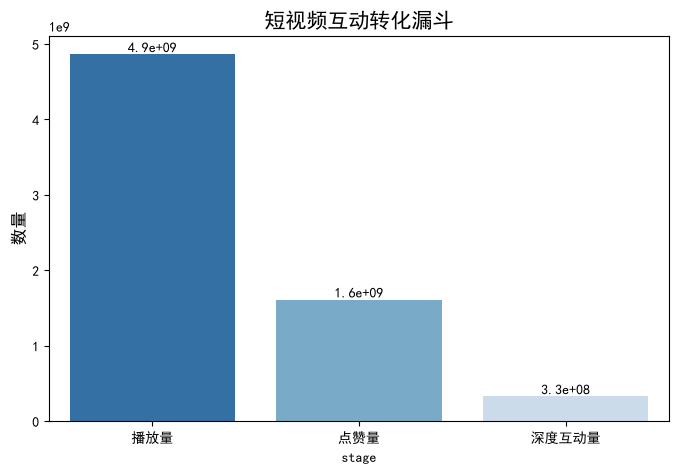

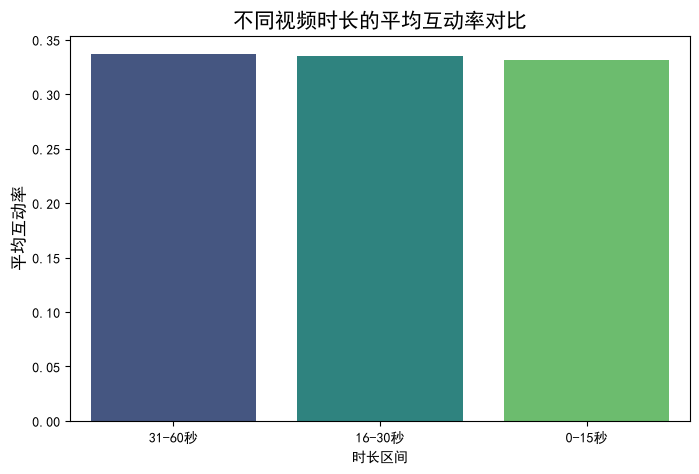

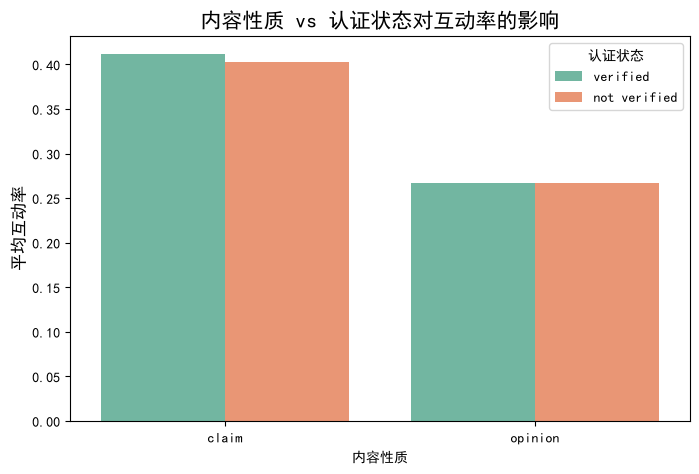

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import sqlite3

# 解决图表中文显示和负号显示问题
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS'] 
plt.rcParams['axes.unicode_minus'] = False

# 确保图片保存的文件夹存在
os.makedirs("../report/figures", exist_ok=True)

# 为了防止变量丢失，这里重新连接一下数据库（确保你已经运行过前面的 SQL 代码）
# 如果你前面的 conn 还在，这里可以直接覆盖，没问题
conn = sqlite3.connect(":memory:")
df.to_sql("behavior", conn, index=False, if_exists="replace")

# ==========================================
# 图 1：短视频转化漏斗（视频级：播放 -> 点赞 -> 深度互动）
# ==========================================
sql_funnel = """
SELECT 
    SUM(video_view_count) AS 播放量,
    SUM(video_like_count) AS 点赞量,
    SUM(video_comment_count + video_share_count) AS 深度互动量
FROM behavior
"""
funnel_df = pd.read_sql(sql_funnel, conn).T.reset_index()
funnel_df.columns = ['stage', 'count']

plt.figure(figsize=(8, 5))
# 【修改点】：加上了 hue='stage' 和 legend=False
sns.barplot(data=funnel_df, x='stage', y='count', hue='stage', palette='Blues_r', legend=False)
plt.title("短视频互动转化漏斗", fontsize=15)
plt.ylabel("数量", fontsize=12)

# 在柱子上标数字
for i in range(len(funnel_df)):
    plt.text(i, funnel_df['count'][i], f"{funnel_df['count'][i]:.1e}", ha='center', va='bottom')

plt.savefig("../report/figures/funnel.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# 图 2：视频时长与互动率对比图
# ==========================================
# 重新查询一下时长数据（防止变量没跑）
sql_duration = """
SELECT duration_bucket AS 时长区间, COUNT(*) AS 视频数, ROUND(AVG(interact_rate), 4) AS 平均互动率
FROM behavior GROUP BY duration_bucket ORDER BY 平均互动率 DESC
"""
res2 = pd.read_sql(sql_duration, conn)

plt.figure(figsize=(8, 5))
plot_df = res2[res2['时长区间'] != '60秒以上']
# 【修改点】：加上了 hue='时长区间' 和 legend=False
sns.barplot(data=plot_df, x='时长区间', y='平均互动率', hue='时长区间', palette='viridis', legend=False)
plt.title("不同视频时长的平均互动率对比", fontsize=15)
plt.ylabel("平均互动率", fontsize=12)

plt.savefig("../report/figures/duration_interact.png", dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# 图 3：内容性质与认证状态交叉对比图
# ==========================================
# 重新查询交叉数据
sql_cross = """
SELECT claim_status AS 内容性质, verified_status AS 认证状态, COUNT(*) AS 视频数, ROUND(AVG(interact_rate), 4) AS 平均互动率
FROM behavior GROUP BY claim_status, verified_status ORDER BY 平均互动率 DESC
"""
res3 = pd.read_sql(sql_cross, conn)

plt.figure(figsize=(8, 5))
# 这里本来就有 hue，所以没报错，保持原样即可
sns.barplot(data=res3, x='内容性质', y='平均互动率', hue='认证状态', palette='Set2')
plt.title("内容性质 vs 认证状态对互动率的影响", fontsize=15)
plt.ylabel("平均互动率", fontsize=12)

plt.savefig("../report/figures/claim_verified.png", dpi=300, bbox_inches="tight")
plt.show()
